In [1]:
import numpy as np
import sympy as sp
from scipy.integrate import quad
import matplotlib.pyplot as plt
import math
import time
from scipy.linalg import hankel
from tqdm import tqdm
import pandas as pd

In [2]:
# precisao = 1e-13

tmax = 2000
rsv = 25
numMax = 40001
M = 1.0
L = 2
aGaussiana, bGaussiana = 30, 2
pertubation_params = (aGaussiana, bGaussiana)

In [3]:
def genelist(a, b, n):
    return np.linspace(a, b, int(n))

a = input('digite o extremo inferior: ');
b = input('digite o extremo superior: ');
eps = input('entre a precisao: ');
i =1;

f = @(x) exp(x)-x^2-3;
%f = inline(exp(x)-x^2-3)
if f(a) * f(b)>0
    disp('Sem raizes');
else
    fprintf('iteracao   valor   erro cometido\n');
    while (b-a)>eps
        x=(a+b)/2;
        if f(x)*f(a)<0
            b=x;
        else
            a=x;
        end
        erro = abs((b-a)/b);
        fprintf('%5d %19.5f %19.2e \n', i, x, erro);
        i=i+1;
    end
    fprintf('O valor da raiz eh %8.5f \n', x);
end

In [4]:
# import numpy as np

# def f(r, rs, M):
#     return r + 2 * M * np.log(r / (2 * M) - 1) - rs

# def findzero(f, range, tor):
#     if not callable(f):
#         raise TypeError("O argumento 'f' precisa ser uma função (ex: lambda x: ... ou def ...)")
    
#     # Converte o intervalo para floats reais (equivalente ao // Re)
#     range_arr = np.array(range, dtype=float)
#     # fr = f /@ (range {1 + 10^-15, 1 - 10^-15}) // Re;
#     deslocamento = np.array([1.0+1e-15, 1.0-1e-15])
#     range_deslocado = range_arr * deslocamento
#     fr = np.array([np.real(f(range_deslocado[0])), np.real(f(range_deslocado[1]))])

#     # x0 = Mean@range // Re;
#     x0 = np.real(np.mean(range_arr))

#     # range1 = If[Re[f[x0]*fr[[1]]] > 0, {x0, range[[2]]}, {range[[1]], x0}] // Re;
#     if np.real(f(x0) * fr[0]) > 0:
#         range1 = np.array([x0, range_arr[1]])
#     else:
#         range1 = np.array([range_arr[0], x0])

#     range1 = np.real(range1)
#     # print(f"range1 = {range1}")
    
#     # While[Abs@First@Differences@range1 > tor, ...
#     while abs(range1[1] - range1[0])>tor:
#         x0 = np.real(np.mean(range1))
#         if np.real(f(x0) * fr[0])>0:
#             range1 = [x0, range1[1]]
#         else:
#             range1 = [range1[0], x0]

#         range1 = np.real(range1)
#     return {'x': float(x0)}



In [5]:
def findrvalue_vetorizado(rstarlist, M, tol=1e-12, max_iter=100):
    """
    Resolve r* = r + 2M*ln(r/(2M) - 1) para r, dado um array de r*,
    usando Newton-Raphson vetorizado (substitui a bisseção ponto a ponto).
    """
    # chute inicial: para r grande, r* ≈ r (assintoticamente)
    r = np.maximum(rstarlist, 2 * M * 1.001)

    for it in range(max_iter):
        fval = r + 2 * M * np.log(r / (2 * M) - 1) - rstarlist
        fprime = 1.0 + 2 * M / (r - 2 * M)

        r_new = r - fval / fprime

        # segurança: nunca deixar cair em r <= 2M (log diverge)
        r_new = np.where(r_new <= 2 * M, (r + 2 * M) / 2, r_new)

        delta = np.max(np.abs(r_new - r))
        r = r_new

        if delta < tol:
            break
        # else:
        #     # print(f"AVISO: Newton não convergiu em {max_iter} iterações.")
        #     # print(f"Maior delta residual: {delta:.3e}")

    return r

In [6]:
# rstar = 25
# M = 1.0
# resultado = findzero(lambda r: f(r, rstar, M), [2 * M + 1e-15, 10000.0], 1e-6)
# print(f"Resultado do findzero: r é aproximadamente {resultado['x']:.6f}")

In [7]:
def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
    av, bv = pertubation_params
    rsmax = 2 * tmax
    rstarlist = genelist(rsv - rsmax/2.0, rsv + rsmax/2.0, numMax)
    
    # def findrvalue(rs_target, M):
    #     #[2 * M + 1e-15, 10000.0] intervalo onde encontrar a raiz, 1e-6 é a tolerância, tendo relação dentro de ln, r/2m-1 >0, portanto r>2m
    #     return findzero(lambda r: f(r, rs_target, M), [2*M, 10000.0], precisao)['x']

    hr = float(np.diff(rstarlist[:2])[0])
    # print(f"rstarlist[0], rstarlist[1]: {rstarlist[0]}, {rstarlist[1]}"
    # )
    # print(f"rstarlist[1] - rstarlist[0]: {rstarlist[1] - rstarlist[0]}")
    # print(f"hr: {hr}")
    ht =0.5 * hr 
    print(f"ht: {ht}")

    inicio = time.time()
    # rlist0 = np.array([findrvalue(rs, M) for rs in rstarlist], dtype = float)
    rlist0 = findrvalue_vetorizado(rstarlist, M)
    tempo_execucao  = time.time() - inicio
    print(f"Tempo de execução para encontrar rlist0: {tempo_execucao:.6f} segundos")

    rlist = rlist0

    def V_potencial(rlist, L, M):
        return (1.0 - 2* M/rlist) * (L*(L+1)/rlist**2 - 6 *M/rlist**3)

    Vv = V_potencial(rlist, L, M)

    ii = 1
    psi0 = np.zeros(len(rlist))
    psi1 = ht * np.exp(-((rstarlist - av)**2) / (2 * (bv**2)))
    length = int((numMax - 1) / 2)
    psi_collect = np.zeros(length)

    inicio_loop = time.time()
    for ii in tqdm(range(1, length+1), desc="Evoluindo PSI"):
        Vv = Vv[1:-1]
        psi2 = (
            2 * psi1[1:-1] 
            - psi0[1:-1] 
            - (ht**2) * Vv * psi1[1:-1] 
            + (ht**2 / hr**2) * (psi1[:-2] - 2 * psi1[1:-1] + psi1[2:])
        )
        # if ii == 1:
        #     print(f"rstarlist[length - ii]: {rstarlist[length - ii]}")
        #     print(f"(ht**2): {ht**2}")
        #     print(f"psi0[length - ii]: {psi0[length - ii]}")
        #     print(f"psi1[length - ii]: {psi1[length - ii]}")
        #     print(f"Vv[length - ii]: {Vv[length - ii]}")
        #     print(f"(psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2): {(psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2)}")
        #     print(f"psi2[length - ii]: {psi2[length - ii - 1]}")
        #     print(f"psi2 = -(ht**2) * ((psi0[1:-1] / (ht**2)) - (2 * psi1[1:-1] / (ht**2)) + (Vv * psi1[1:-1]) - ((psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2))) --> {psi2[length - ii - 1]} = {-(ht**2)} * {((psi0[length - ii] / (ht**2)) - (2 * psi1[length - ii] / (ht**2)) + (Vv[length - ii] * psi1[length - ii]) - ((psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2))) }")
        psi0 = psi1[1:-1]
        psi1 = psi2

        psi_collect[ii-1] = psi1[length - ii]
        

    tempo_execucao_loop  = time.time() - inicio_loop
    print(f"Tempo de execução do loop: {tempo_execucao_loop:.6f} segundos")
    return ht, psi_collect


In [8]:
def plotEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))
    plt.plot(t, psi, lw=2)

    t_max = t[-1]
    plt.xticks(np.arange(0, t_max + 1, 100))
    plt.xlabel("t")
    plt.ylabel(r"$\Psi$")
    plt.grid(True)
    plt.title(title)
    plt.show()


def plotLogEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

ht: 0.049999999999954525
Tempo de execução para encontrar rlist0: 0.035265 segundos


Evoluindo PSI: 100%|██████████| 20000/20000 [00:02<00:00, 9017.62it/s] 


Tempo de execução do loop: 2.302094 segundos


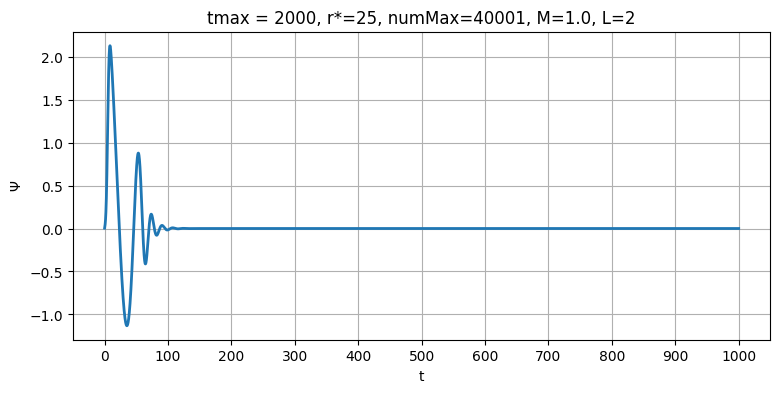

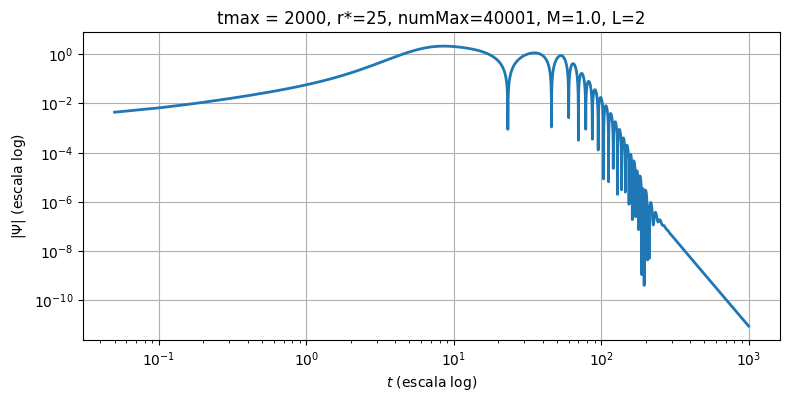

In [9]:
# def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
test1 = getEvo(tmax, rsv, numMax, M, L, pertubation_params)
title_str = f"tmax = {tmax}, r*={rsv}, numMax={numMax}, M={M}, L={L}"
plotEvolution(
    test1,
    title_str
)
plotLogEvolution(
    test1,
    title_str
)

In [10]:
def plotLogEvolutionmod(test, title=""):

    ht, psi = test
    # print(f"len(psi): {len(psi)}")
    # print(f"ht: {ht}")

    t = ht * np.arange(3000, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi[2999:]),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

Default Return (full=False, cov=False)When you run the default configuration, it only returns the coefficients array (p).Shape: (deg + 1,) where deg is the polynomial degree you requested.Order: Highest degree term to lowest degree term (\(c_n, c_{n-1}, ..., c_0\)).Example: Fitting a line (y = mx + b) using deg=1 returns [m, b].

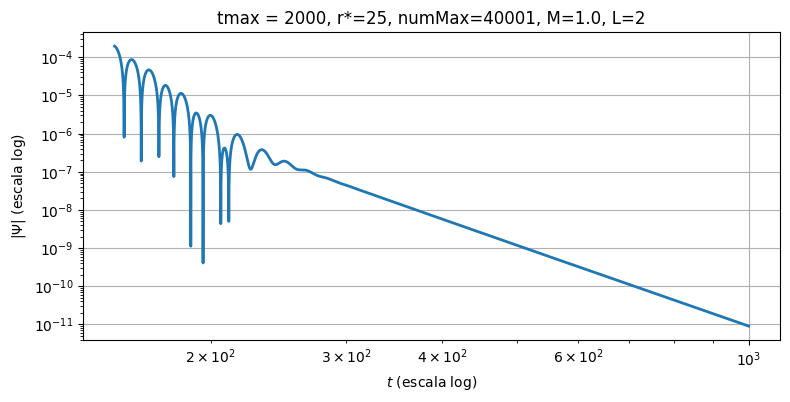

Inclinação = -7.024160
Intercepto = 23.115432


In [11]:
plotLogEvolutionmod(
    test1,
    title_str
)


ht, psi = test1

# Tempo correspondente
t = ht * np.arange(1, len(psi) + 1)

# Intervalo desejado
inicio = 4000
fim = 9001      # o último índice (9000) é incluído

t_fit = t[inicio:fim]
psi_fit = np.abs(psi[inicio:fim])

# Evita log(0)
mask = psi_fit > 0

x = np.log(t_fit[mask])
y = np.log(psi_fit[mask])

# Ajuste linear
coef = np.polyfit(x, y, 1)

slope = coef[0]
intercept = coef[1]

print(f"Inclinação = {slope:.6f}")
print(f"Intercepto = {intercept:.6f}")

If a static I,-pole field is present outside the star, prior to the onset of collapse,
the field will fall off as t
'"'". If there is no field
initially outside the star, but an l-pole perturbation develops during the collapse process, it will
fall off as t^(2l+3) a.t la.rge time

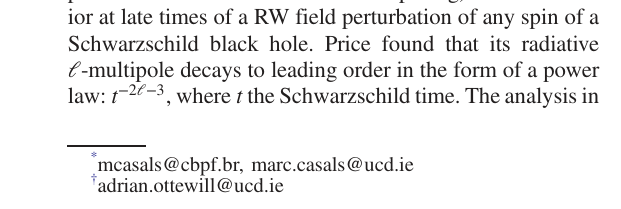

10.1103/PhysRevD.92.124055

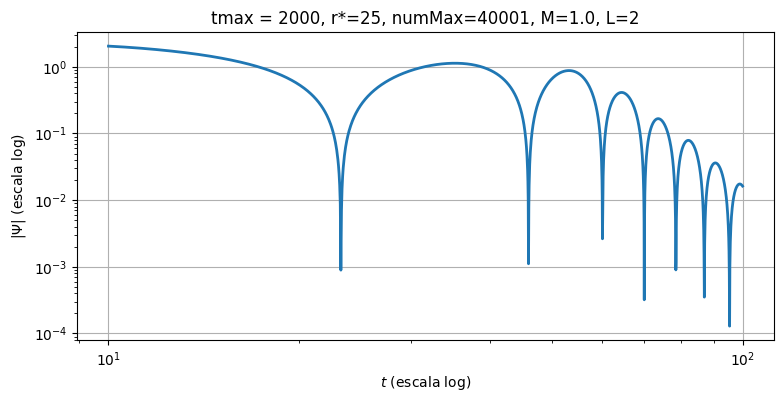

In [12]:
def plotLogEvolution20200(test, title=""):

    ht, psi = test
    # print(f"len(psi): {len(psi)}")
    # print(f"ht: {ht}")

    t = ht * np.arange(200, 2000)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi[199:1999]),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()


plotLogEvolution20200(
    test1,
    title_str
)

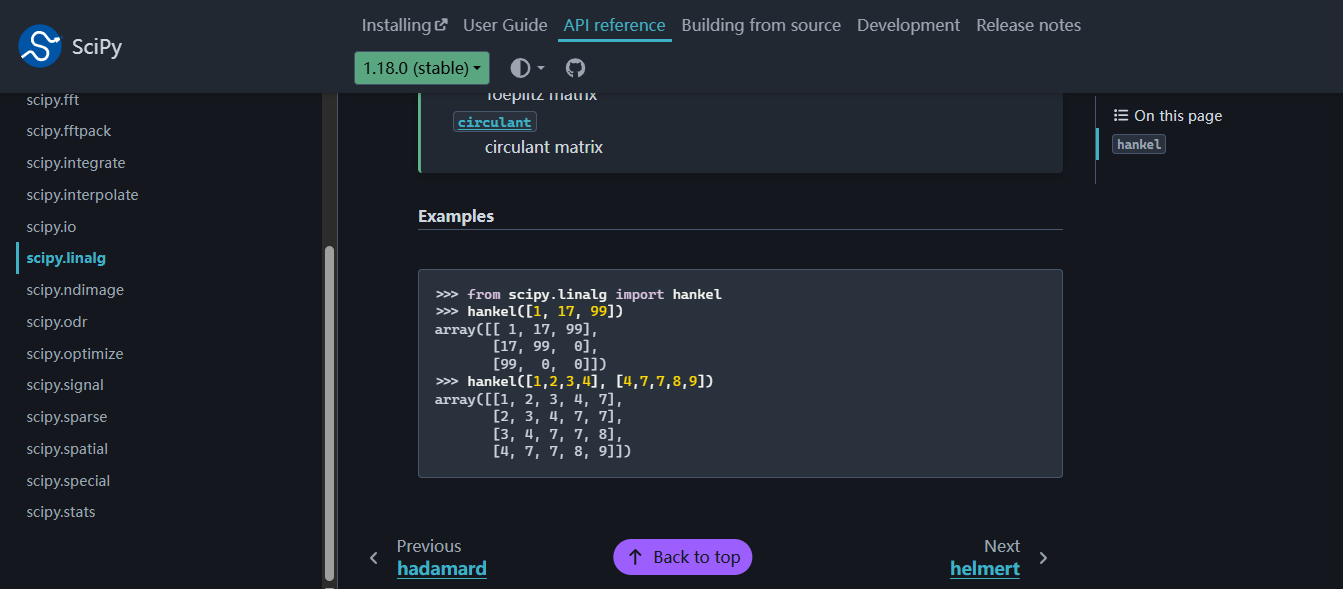

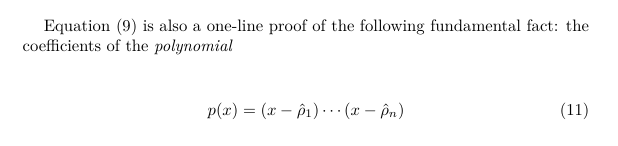

In [13]:
# pronyi = 0
# pronyf = len(psi)-1
# #len(psi) = 10000
# print(f"A seção selecionado para análise de Prony é de {pronyi} a {pronyf}")
# ht, psi = test1
# range_array = psi[pronyi:pronyf]
# n = 6


# num_colunas_total = n + 1  # 6 colunas para A + 1 coluna para o vetor b (total = 7)
# num_linhas = len(range_array) - num_colunas_total + 1  # 500 - 7 + 1 = 494 linhas

# # 3. Construir a Matriz de Hankel deslizante correta
# # Primeira coluna: os primeiros num_linhas pontos
# # Última linha: os últimos num_colunas_total pontos
# c = range_array[:num_linhas]
# r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #(494-1 : 494-1+7) = 493:500

# matriz_hankel_completa = hankel(c, r)

# # 4. Separar em Matriz A (300x6) e Vetor b (300x1)
# # Se quiser limitar estritamente a 300 linhas:
# # matriz_hankel_completa = matriz_hankel_completa[:300, :]

# matriz_A = matriz_hankel_completa[:, :n]  # Colunas de Psi_0 até Psi_5 (300x6)
# vetor_b = -matriz_hankel_completa[:, n]  # Coluna Psi_6 com sinal trocado (300x1)
# # print(f"vetor_b: {vetor_b}")
# print(f"matriz_a.shape: {matriz_A.shape}, vetor_b.shape: {vetor_b.shape}")

# p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
#     matriz_A, vetor_b, rcond=None
# )

# # 5. Salvar a Matriz A e o Vetor b em uma planilha do Excel
# # Criamos um DataFrame do pandas organizando as colunas
# # colunas_nomes = [f"Psi_k+{i}" for i in range(n)] + ["-Psi_k+6 (vetor_b)"]
# # df_excel = pd.DataFrame(matriz_hankel_completa, columns=colunas_nomes)

# # # Salva no arquivo Excel
# # nome_arquivo = "matriz_hankel_prony.xlsx"
# # df_excel.to_csv(nome_arquivo, index=False)

# # print(f"Matriz de Hankel criada com sucesso! Formato: {matriz_hankel_completa.shape}")
# # print(f"Arquivo salvo como: '{nome_arquivo}'")

# #==========================================================================================
# # 1. Agrupar todos os coeficientes em ordem DECRESCENTE de potência
# # p_coef vem do lstsq: [p0, p1, p2, p3, p4, p5]
# # O termo de maior grau p6 é igual a 1.0
# coefs_polinomio = [1.0] + list(p_coef[::-1])

# # 2. Encontrar os rhos (\hat{\rho}_j) calculando as raízes do polinômio
# rhos = np.roots(coefs_polinomio)

# # print("Os 'rhos' (raízes complexas) encontrados são:")
# # print(rhos)

# dt = ht

# # Converter os 'rhos' para as frequências físicas omegas
# omegas = 1j * np.log(rhos) / dt

# # Exibir os resultados
# for j, w in enumerate(omegas):
#     print(
#         f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}"
#     )

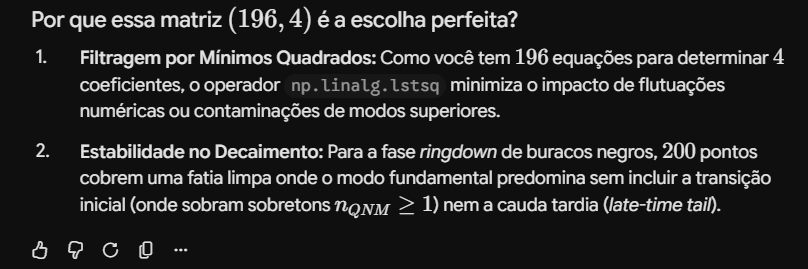

In [ ]:
# # n =0 (overtone) — janela definida em TEMPO FÍSICO, não em número de amostras fixo

# ht, psi = test1
# # 2*pi / 0.34671 = 18.1

# # --- Parâmetros físicos da janela (o que muda de verdade) ---
# t_inicio_janela = 5.0        # pula o transiente inicial antes da ringdown se estabelecer
# duracao_janela = 30.0        # ~1.5-2 períodos do overtone n=1 (T ≈ 18.1)
# n = 10                        # ordem do polinômio de Prony

# # --- Conversão para índices, usando o ht ATUAL (funciona igual para qualquer numMax) ---
# pronyi = int(round(t_inicio_janela / ht))
# pronyf = int(round((t_inicio_janela + duracao_janela) / ht))

# passo = 1
# i = 0
# itotal = (len(psi) - pronyf) / passo
# nome_arquivo = "resultados_prony_n0_passo1.txt"

# with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
#     while True:
#         pronyireal = pronyi + i * passo
#         pronyfreal = pronyf + i * passo
#         range_array = psi[pronyireal:pronyfreal]

#         t_ini_real = pronyireal * ht
#         t_fim_real = pronyfreal * ht

#         arquivo.write(f"\n")
#         arquivo.write(
#             f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal} "
#             f"(t = {t_ini_real:.3f} a {t_fim_real:.3f})\n"
#         )

#         num_colunas_total = n + 1
#         num_linhas = len(range_array) - num_colunas_total + 1

#         c = range_array[:num_linhas]
#         r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total]

#         matriz_hankel_completa = hankel(c, r)

#         matriz_A = matriz_hankel_completa[:, :n]
#         vetor_b = -matriz_hankel_completa[:, n]

#         p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
#             matriz_A, vetor_b, rcond=None
#         )

#         # --- Diagnóstico de condicionamento (novo) ---
#         cond_number = valores_singulares[0] / valores_singulares[-1]
#         arquivo.write(f"Número de condição da matriz A: {cond_number:.3e}\n")

#         coefs_polinomio = [1.0] + list(p_coef[::-1])
#         rhos = np.roots(coefs_polinomio)

#         dt = ht
#         omegas = 1j * np.log(rhos) / dt

#         for j, w in enumerate(omegas):
#             arquivo.write(
#                 f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}\n"
#             )
#         i += 1
#         if i > itotal:
#             break

# print(f"Janela usada: pronyi={pronyi}, pronyf={pronyf} "
#       f"(t = {pronyi*ht:.3f} a {pronyf*ht:.3f}), ht={ht}")

In [14]:
# n = 0
pronyi = 0
pronyf = 180
#len(psi) = 10000, t = 0.1 * len(psi)
#se t = 300, pronyf = 3000
passo = 1
ht, psi = test1
i = 0
n = 4
itotal = (len(psi) - pronyf)/passo
nome_arquivo = "resultados_prony_n0_passo1.txt"
with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
    while True:
        pronyireal = pronyi + i * passo
        pronyfreal = pronyf + i * passo
        range_array = psi[pronyireal:pronyfreal]
        arquivo.write(f"\n")
        arquivo.write(f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal}\n")

        num_colunas_total = n + 1  # 6 colunas para A + 1 coluna para o vetor b (total = 7)
        num_linhas = len(range_array) - num_colunas_total + 1  # 500 - 7 + 1 = 494 linhas

        c = range_array[:num_linhas]
        r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #(494-1 : 494-1+7) = 493:500

        matriz_hankel_completa = hankel(c, r)


        matriz_A = matriz_hankel_completa[:, :n]  # Colunas de Psi_0 até Psi_5 (300x6)
        vetor_b = -matriz_hankel_completa[:, n]  # Coluna Psi_6 com sinal trocado (300x1)
        # print(f"vetor_b: {vetor_b}")
        # print(f"matriz_a.shape: {matriz_A.shape}, vetor_b.shape: {vetor_b.shape}")

        p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
            matriz_A, vetor_b, rcond=None
        )

        coefs_polinomio = [1.0] + list(p_coef[::-1])

        # 2. Encontrar os rhos (\hat{\rho}_j) calculando as raízes do polinômio
        rhos = np.roots(coefs_polinomio)

        # print("Os 'rhos' (raízes complexas) encontrados são:")
        # print(rhos)

        dt = ht

        # Converter os 'rhos' para as frequências físicas omegas
        omegas = 1j * np.log(rhos) / dt

        # Exibir os resultados
        for j, w in enumerate(omegas):
            arquivo.write(
                f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}\n"
            )
        i+=1
        if i> itotal:
            break

In [25]:
import numpy as np

omega_R_n0 = 0.37367
omega_R_n1 = 0.34671
omega_R_n2 = 0.30105

fator_periodos = 1.5  # quantos períodos de folga você quer

T_n0 = 2 * np.pi / omega_R_n0
T_n1 = 2 * np.pi / omega_R_n1
T_n2 = 2 * np.pi / omega_R_n2

duracao_janela_n0 = fator_periodos * T_n0
duracao_janela_n1 = fator_periodos * T_n1
duracao_janela_n2 = fator_periodos * T_n2

print(f"n=0: T={T_n0:.3f}, duracao_janela={duracao_janela_n0:.3f}")
print(f"n=1: T={T_n1:.3f}, duracao_janela={duracao_janela_n1:.3f}")
print(f"n=2: T={T_n2:.3f}, duracao_janela={duracao_janela_n2:.3f}")

n=0: T=16.815, duracao_janela=25.222
n=1: T=18.122, duracao_janela=27.183
n=2: T=20.871, duracao_janela=31.306


In [16]:
import re

# Arquivos de entrada e saída
arquivo_entrada = "resultados_prony_n0_passo1.txt"
arquivo_saida = "resultados_n0_filtrados_4digitos.txt"

# Valores teóricos do QNM fundamental (n = 0)
omega_R_teorico = 0.37367
omega_I_teorico = 0.08896

# Margens relativas calculadas separadamente
MARGEM_R = 0.00005 / omega_R_teorico  # ≈ 0.0001338 (0.01338%)
MARGEM_I = 0.00005 / omega_I_teorico  # ≈ 0.0005620 (0.05620%)

tol_R = omega_R_teorico * MARGEM_R  # Dá exatamente 0.00005
tol_I = omega_I_teorico * MARGEM_I  # Dá exatamente 0.00005

secao_atual = ""

with open(arquivo_entrada, "r", encoding="utf-8") as f_in, \
     open(arquivo_saida, "w", encoding="utf-8") as f_out:

    f_out.write("=== RESULTADOS FILTRADOS PARA O QNM FUNDAMENTAL (4 CASAS DECIMAIS) ===\n")
    f_out.write(f"Alvo esperado: |omega_R| ≈ {omega_R_teorico} | omega_I ≈ {omega_I_teorico}\n")
    f_out.write(f"Intervalo R aceito: [{omega_R_teorico - tol_R:.5f} a {omega_R_teorico + tol_R:.5f}]\n")
    f_out.write(f"Intervalo I aceito: [{omega_I_teorico - tol_I:.5f} a {omega_I_teorico + tol_I:.5f}]\n\n")

    for linha in f_in:
        # Guarda a informação da janela
        if "A seção selecionado" in linha or "Iteração" in linha:
            secao_atual = linha.strip()

        # Procura por linhas do tipo "Modo X: omega_R = ... | omega_I = ..."
        match = re.search(r"Modo\s+(\d+):\s+omega_R\s*=\s*([-+]?\d*\.?\d+)\s*\|\s*omega_I\s*=\s*([-+]?\d*\.?\d+)", linha)
        
        if match:
            modo_num = match.group(1)
            omega_R = float(match.group(2))
            omega_I = float(match.group(3))

            # Filtro com tolerâncias separadas
            condicao_R = abs(abs(omega_R) - omega_R_teorico) <= tol_R
            condicao_I = abs(omega_I - omega_I_teorico) <= tol_I

            if condicao_R and condicao_I:
                if secao_atual:
                    f_out.write(f"{secao_atual}\n")
                    secao_atual = ""  # Limpa para evitar reescrever o mesmo cabeçalho
                
                f_out.write(f"  Modo {modo_num}: omega_R = {omega_R:.8f} | omega_I = {omega_I:.8f}\n\n")

print(f"Filtragem para 4 casas decimais concluída! Verifique '{arquivo_saida}'.")

Filtragem para 4 casas decimais concluída! Verifique 'resultados_n0_filtrados_4digitos.txt'.


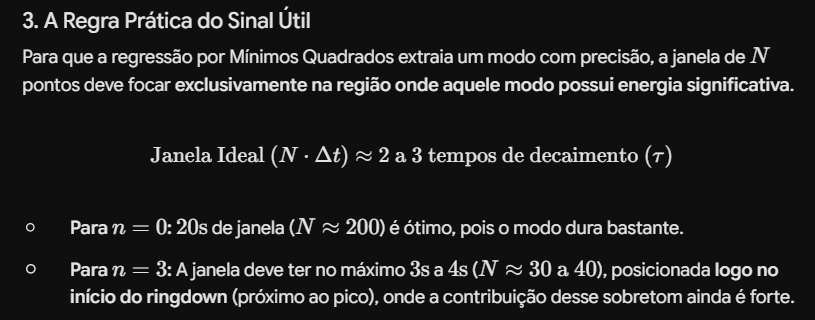

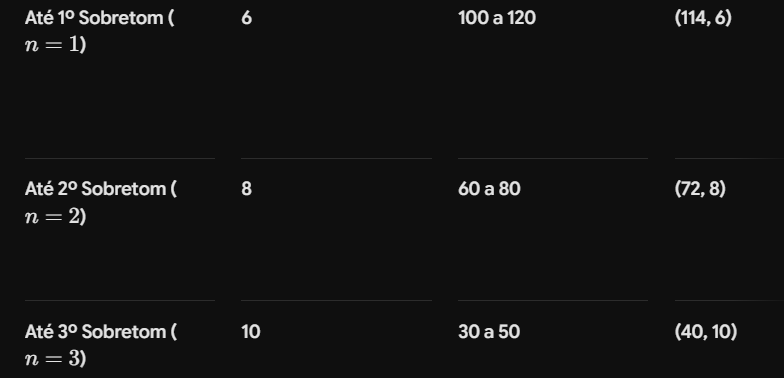

Alvo da Análise,Ordem nProny​,Amostras (N),Dimensão da Matriz A,Justificativa
Fundamental (n=0),4,200,"(196, 4)",Janela longa (T=20s) para isolar a frequência que sobrevive por mais tempo.
Até 1º Sobretom (n=1),6,100 a 120,"(114, 6)",Reduz a janela (T≈10-12s) para pegar a região onde n=1 ainda tem amplitude considerável.
Até 2º Sobretom (n=2),8,60 a 80,"(72, 8)",Janela mais curta (T≈6-8s) focada logo após o pico do ringdown.
Até 3º Sobretom (n=3),10,30 a 50,"(40, 10)","Janela muito curta (T≈3-5s) colada ao pico da fusão, onde os sobretons rápidos ainda não atenuaram."

In [ ]:
# n = 1 (overtone) — janela definida em TEMPO FÍSICO, não em número de amostras fixo

ht, psi = test1
# 2*pi / 0.34671 = 18.1

# --- Parâmetros físicos da janela (o que muda de verdade) ---
t_inicio_janela = 5.0        # pula o transiente inicial antes da ringdown se estabelecer
duracao_janela = 30.0        # ~1.5-2 períodos do overtone n=1 (T ≈ 18.1)
n = 10                        # ordem do polinômio de Prony

# --- Conversão para índices, usando o ht ATUAL (funciona igual para qualquer numMax) ---
pronyi = int(round(t_inicio_janela / ht))
pronyf = int(round((t_inicio_janela + duracao_janela) / ht))

passo = 1
i = 0
itotal = (len(psi) - pronyf) / passo
nome_arquivo = "resultados_prony_n1_passo1.txt"

with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
    while True:
        pronyireal = pronyi + i * passo
        pronyfreal = pronyf + i * passo
        range_array = psi[pronyireal:pronyfreal]

        t_ini_real = pronyireal * ht
        t_fim_real = pronyfreal * ht

        arquivo.write(f"\n")
        arquivo.write(
            f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal} "
            f"(t = {t_ini_real:.3f} a {t_fim_real:.3f})\n"
        )

        num_colunas_total = n + 1
        num_linhas = len(range_array) - num_colunas_total + 1

        c = range_array[:num_linhas]
        r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total]

        matriz_hankel_completa = hankel(c, r)

        matriz_A = matriz_hankel_completa[:, :n]
        vetor_b = -matriz_hankel_completa[:, n]

        p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
            matriz_A, vetor_b, rcond=None
        )

        # --- Diagnóstico de condicionamento (novo) ---
        cond_number = valores_singulares[0] / valores_singulares[-1]
        arquivo.write(f"Número de condição da matriz A: {cond_number:.3e}\n")

        coefs_polinomio = [1.0] + list(p_coef[::-1])
        rhos = np.roots(coefs_polinomio)

        dt = ht
        omegas = 1j * np.log(rhos) / dt

        for j, w in enumerate(omegas):
            arquivo.write(
                f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}\n"
            )
        i += 1
        if i > itotal:
            break

print(f"Janela usada: pronyi={pronyi}, pronyf={pronyf} "
      f"(t = {pronyi*ht:.3f} a {pronyf*ht:.3f}), ht={ht}")

Janela usada: pronyi=100, pronyf=700 (t = 5.000 a 35.000), ht=0.049999999999954525


In [ ]:
# #n = 1
# pronyi = 0
# pronyf = 600
# passo = 1
# ht, psi = test1
# i = 0
# n = 10
# itotal = (len(psi) - pronyf)/passo
# nome_arquivo = "resultados_prony_n1_passo1.txt"
# with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
#     while True:
#         pronyireal = pronyi + i * passo
#         pronyfreal = pronyf + i * passo
#         range_array = psi[pronyireal:pronyfreal]
#         arquivo.write(f"\n")
#         arquivo.write(f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal}\n")

#         num_colunas_total = n + 1  # 6 colunas para A + 1 coluna para o vetor b (total = 7)
#         num_linhas = len(range_array) - num_colunas_total + 1  # 500 - 7 + 1 = 494 linhas

#         c = range_array[:num_linhas]
#         r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #(494-1 : 494-1+7) = 493:500

#         matriz_hankel_completa = hankel(c, r)


#         matriz_A = matriz_hankel_completa[:, :n]  # Colunas de Psi_0 até Psi_5 (300x6)
#         vetor_b = -matriz_hankel_completa[:, n]  # Coluna Psi_6 com sinal trocado (300x1)
#         # print(f"vetor_b: {vetor_b}")
#         # print(f"matriz_a.shape: {matriz_A.shape}, vetor_b.shape: {vetor_b.shape}")

#         p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
#             matriz_A, vetor_b, rcond=None
#         )

#         coefs_polinomio = [1.0] + list(p_coef[::-1])

#         # 2. Encontrar os rhos (\hat{\rho}_j) calculando as raízes do polinômio
#         rhos = np.roots(coefs_polinomio)

#         # print("Os 'rhos' (raízes complexas) encontrados são:")
#         # print(rhos)

#         dt = ht

#         # Converter os 'rhos' para as frequências físicas omegas
#         omegas = 1j * np.log(rhos) / dt

#         # Exibir os resultados
#         for j, w in enumerate(omegas):
#             arquivo.write(
#                 f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}\n"
#             )
#         i+=1
#         if i> itotal:
#             break

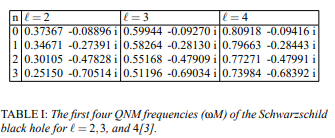

https://www.scielo.br/j/bjp/a/hWr4kY7cZCGxDhdrF7JmDGh/?format=pdf&lang=en

In [31]:
import re

# Arquivos de entrada e saída
arquivo_entrada = "resultados_prony_n1_passo1.txt"
arquivo_saida = "resultados_n1_filtrados_4casas.txt"

# Valores teóricos do 1º Sobretom (n = 1)
omega_R_teorico = 0.34671
omega_I_teorico = 0.27391

# Margens relativas desejadas (0.15% e 0.2%)
MARGEM_R = 0.0015  # 0.15% / 100
MARGEM_I = 0.0020  # 0.20% / 100

# Tolerâncias absolutas calculadas a partir das porcentagens
tol_R = omega_R_teorico * MARGEM_R  # ≈ 0.000208
tol_I = omega_I_teorico * MARGEM_I  # ≈ 0.001917

secao_atual = ""

with open(arquivo_entrada, "r", encoding="utf-8") as f_in, \
     open(arquivo_saida, "w", encoding="utf-8") as f_out:

    f_out.write("=== RESULTADOS FILTRADOS PARA O OVERTONE n=1 (4 CASAS DECIMAIS) ===\n")
    f_out.write(f"Alvo esperado: |omega_R| ≈ {omega_R_teorico} | omega_I ≈ {omega_I_teorico}\n")
    f_out.write(f"Intervalo R aceito: [{omega_R_teorico - tol_R:.5f} a {omega_R_teorico + tol_R:.5f}]\n")
    f_out.write(f"Intervalo I aceito: [{omega_I_teorico - tol_I:.5f} a {omega_I_teorico + tol_I:.5f}]\n\n")

    for linha in f_in:
        # Guarda a informação da janela
        if "A seção selecionado" in linha or "Iteração" in linha:
            secao_atual = linha.strip()

        # Procura por linhas do tipo "Modo X: omega_R = ... | omega_I = ..."
        match = re.search(r"Modo\s+(\d+):\s+omega_R\s*=\s*([-+]?\d*\.?\d+)\s*\|\s*omega_I\s*=\s*([-+]?\d*\.?\d+)", linha)
        
        if match:
            modo_num = match.group(1)
            omega_R = float(match.group(2))
            omega_I = float(match.group(3))

            # Filtro com tolerâncias separadas
            condicao_R = abs(abs(omega_R) - omega_R_teorico) <= tol_R
            condicao_I = abs(omega_I - omega_I_teorico) <= tol_I

            if condicao_R and condicao_I:
                if secao_atual:
                    f_out.write(f"{secao_atual}\n")
                    secao_atual = ""  # Limpa para evitar reescrever o mesmo cabeçalho
                
                f_out.write(f"  Modo {modo_num}: omega_R = {omega_R:.8f} | omega_I = {omega_I:.8f}\n\n")

print(f"Filtragem para 4 casas decimais (n=1) concluída! Verifique '{arquivo_saida}'.")

Filtragem para 4 casas decimais (n=1) concluída! Verifique 'resultados_n1_filtrados_4casas.txt'.


In [20]:
#n = 2
pronyi = 0
pronyf = 40
passo = 1
ht, psi = test1
i = 0
n = 12
itotal = (len(psi) - pronyf)/passo
nome_arquivo = "resultados_prony_n2_passo1.txt"
with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
    while True:
        pronyireal = pronyi + i * passo
        pronyfreal = pronyf + i * passo
        range_array = psi[pronyireal:pronyfreal]
        arquivo.write(f"\n")
        arquivo.write(f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal}\n")

        num_colunas_total = n + 1  # 6 colunas para A + 1 coluna para o vetor b (total = 7)
        num_linhas = len(range_array) - num_colunas_total + 1  # 500 - 7 + 1 = 494 linhas

        c = range_array[:num_linhas]
        r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #(494-1 : 494-1+7) = 493:500

        matriz_hankel_completa = hankel(c, r)


        matriz_A = matriz_hankel_completa[:, :n]  # Colunas de Psi_0 até Psi_5 (300x6)
        vetor_b = -matriz_hankel_completa[:, n]  # Coluna Psi_6 com sinal trocado (300x1)
        # print(f"vetor_b: {vetor_b}")
        # print(f"matriz_a.shape: {matriz_A.shape}, vetor_b.shape: {vetor_b.shape}")

        p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
            matriz_A, vetor_b, rcond=None
        )

        coefs_polinomio = [1.0] + list(p_coef[::-1])

        # 2. Encontrar os rhos (\hat{\rho}_j) calculando as raízes do polinômio
        rhos = np.roots(coefs_polinomio)

        # print("Os 'rhos' (raízes complexas) encontrados são:")
        # print(rhos)

        dt = ht

        # Converter os 'rhos' para as frequências físicas omegas
        omegas = 1j * np.log(rhos) / dt

        # Exibir os resultados
        for j, w in enumerate(omegas):
            arquivo.write(
                f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}\n"
            )
        i+=1
        if i> itotal:
            break

In [21]:
# import re

# # Arquivos de entrada e saída
# arquivo_entrada = "resultados_prony_n2_passo1.txt"
# arquivo_saida = "resultados_n2_filtrados_4casas.txt"

# # Valores teóricos do 2º Sobretom (n = 2)
# omega_R_teorico = 0.30105
# omega_I_teorico = 0.47828

# # Margens relativas calculadas separadamente para 4 casas decimais (±0.0005)
# MARGEM_R = 0.00005 / omega_R_teorico  # ≈ 0.001442 (0.1442%)
# MARGEM_I = 0.00005 / omega_I_teorico  # ≈ 0.001825 (0.1825%)

# tol_R = omega_R_teorico * MARGEM_R  # Dá exatamente 0.0005
# tol_I = omega_I_teorico * MARGEM_I  # Dá exatamente 0.0005

# secao_atual = ""

# with open(arquivo_entrada, "r", encoding="utf-8") as f_in, \
#      open(arquivo_saida, "w", encoding="utf-8") as f_out:

#     f_out.write("=== RESULTADOS FILTRADOS PARA O OVERTONE n=2 (4 CASAS DECIMAIS) ===\n")
#     f_out.write(f"Alvo esperado: |omega_R| ≈ {omega_R_teorico} | omega_I ≈ {omega_I_teorico}\n")
#     f_out.write(f"Intervalo R aceito: [{omega_R_teorico - tol_R:.5f} a {omega_R_teorico + tol_R:.5f}]\n")
#     f_out.write(f"Intervalo I aceito: [{omega_I_teorico - tol_I:.5f} a {omega_I_teorico + tol_I:.5f}]\n\n")

#     for linha in f_in:
#         # Guarda a informação da janela
#         if "A seção selecionado" in linha or "Iteração" in linha:
#             secao_atual = linha.strip()

#         # Procura por linhas do tipo "Modo X: omega_R = ... | omega_I = ..."
#         match = re.search(r"Modo\s+(\d+):\s+omega_R\s*=\s*([-+]?\d*\.?\d+)\s*\|\s*omega_I\s*=\s*([-+]?\d*\.?\d+)", linha)
        
#         if match:
#             modo_num = match.group(1)
#             omega_R = float(match.group(2))
#             omega_I = float(match.group(3))

#             # Filtro com tolerâncias separadas
#             condicao_R = abs(abs(omega_R) - omega_R_teorico) <= tol_R
#             condicao_I = abs(omega_I - omega_I_teorico) <= tol_I

#             if condicao_R and condicao_I:
#                 if secao_atual:
#                     f_out.write(f"{secao_atual}\n")
#                     secao_atual = ""  # Limpa para evitar reescrever o mesmo cabeçalho
                
#                 f_out.write(f"  Modo {modo_num}: omega_R = {omega_R:.8f} | omega_I = {omega_I:.8f}\n\n")

# print(f"Filtragem para 4 casas decimais (n=1) concluída! Verifique '{arquivo_saida}'.")

In [22]:
import re

arquivo_entrada = "resultados_prony_n1_passo1.txt"

omega_R_teorico = 0.34671
omega_I_teorico = 0.27391

secao_atual = ""
candidatos = []

with open(arquivo_entrada, "r", encoding="utf-8") as f_in:
    for linha in f_in:
        if "A seção selecionado" in linha:
            secao_atual = linha.strip()

        match = re.search(
            r"Modo\s+(\d+):\s+omega_R\s*=\s*([-+]?\d*\.?\d+)\s*\|\s*omega_I\s*=\s*([-+]?\d*\.?\d+)",
            linha
        )
        if match:
            modo_num = match.group(1)
            omega_R = float(match.group(2))
            omega_I = float(match.group(3))

            # distância combinada (normalizada) ao alvo teórico
            dist = ((abs(omega_R) - omega_R_teorico) / omega_R_teorico) ** 2 \
                 + ((omega_I - omega_I_teorico) / omega_I_teorico) ** 2

            candidatos.append((dist, secao_atual, modo_num, omega_R, omega_I))

# ordena do mais próximo pro mais distante do alvo teórico
candidatos.sort(key=lambda x: x[0])

print("Top 15 candidatos mais próximos do overtone n=1 teórico:\n")
for dist, secao, modo, wr, wi in candidatos[:15]:
    print(f"{secao}")
    print(f"  Modo {modo}: omega_R = {wr:.8f} | omega_I = {wi:.8f}  "
          f"(dist_norm = {dist:.3e})\n")

Top 15 candidatos mais próximos do overtone n=1 teórico:

A seção selecionado para análise de Prony é de 1665 a 2265 (t = 83.250 a 113.250)
  Modo 7: omega_R = -0.34627679 | omega_I = 0.27407854  (dist_norm = 1.940e-06)

A seção selecionado para análise de Prony é de 1665 a 2265 (t = 83.250 a 113.250)
  Modo 8: omega_R = 0.34627679 | omega_I = 0.27407854  (dist_norm = 1.940e-06)

A seção selecionado para análise de Prony é de 1678 a 2278 (t = 83.900 a 113.900)
  Modo 7: omega_R = -0.34631503 | omega_I = 0.27420610  (dist_norm = 2.466e-06)

A seção selecionado para análise de Prony é de 1678 a 2278 (t = 83.900 a 113.900)
  Modo 8: omega_R = 0.34631503 | omega_I = 0.27420610  (dist_norm = 2.466e-06)

A seção selecionado para análise de Prony é de 1659 a 2259 (t = 82.950 a 112.950)
  Modo 7: omega_R = -0.34608409 | omega_I = 0.27391867  (dist_norm = 3.260e-06)

A seção selecionado para análise de Prony é de 1659 a 2259 (t = 82.950 a 112.950)
  Modo 8: omega_R = 0.34608409 | omega_I = 0.27

In [24]:
import re

arquivo_entrada = "resultados_prony_n2_passo1.txt"

omega_R_teorico = 0.30105
omega_I_teorico = 0.47828

secao_atual = ""
candidatos = []

with open(arquivo_entrada, "r", encoding="utf-8") as f_in:
    for linha in f_in:
        if "A seção selecionado" in linha:
            secao_atual = linha.strip()

        match = re.search(
            r"Modo\s+(\d+):\s+omega_R\s*=\s*([-+]?\d*\.?\d+)\s*\|\s*omega_I\s*=\s*([-+]?\d*\.?\d+)",
            linha
        )
        if match:
            modo_num = match.group(1)
            omega_R = float(match.group(2))
            omega_I = float(match.group(3))

            # distância combinada (normalizada) ao alvo teórico
            dist = ((abs(omega_R) - omega_R_teorico) / omega_R_teorico) ** 2 \
                 + ((omega_I - omega_I_teorico) / omega_I_teorico) ** 2

            candidatos.append((dist, secao_atual, modo_num, omega_R, omega_I))

# ordena do mais próximo pro mais distante do alvo teórico
candidatos.sort(key=lambda x: x[0])

print("Top 15 candidatos mais próximos do overtone n=1 teórico:\n")
for dist, secao, modo, wr, wi in candidatos[:15]:
    print(f"{secao}")
    print(f"  Modo {modo}: omega_R = {wr:.8f} | omega_I = {wi:.8f}  "
          f"(dist_norm = {dist:.3e})\n")

Top 15 candidatos mais próximos do overtone n=1 teórico:

A seção selecionado para análise de Prony é de 1691 a 1731
  Modo 11: omega_R = -0.31129100 | omega_I = 0.44524926  (dist_norm = 5.927e-03)

A seção selecionado para análise de Prony é de 1691 a 1731
  Modo 12: omega_R = 0.31129100 | omega_I = 0.44524926  (dist_norm = 5.927e-03)

A seção selecionado para análise de Prony é de 6181 a 6221
  Modo 10: omega_R = -0.30474983 | omega_I = 0.52184135  (dist_norm = 8.446e-03)

A seção selecionado para análise de Prony é de 6181 a 6221
  Modo 11: omega_R = 0.30474983 | omega_I = 0.52184135  (dist_norm = 8.446e-03)

A seção selecionado para análise de Prony é de 1669 a 1709
  Modo 11: omega_R = -0.27279243 | omega_I = 0.40887082  (dist_norm = 2.987e-02)

A seção selecionado para análise de Prony é de 1669 a 1709
  Modo 12: omega_R = 0.27279243 | omega_I = 0.40887082  (dist_norm = 2.987e-02)

A seção selecionado para análise de Prony é de 1699 a 1739
  Modo 11: omega_R = -0.35046030 | omega